# Baseline model: Ridge regression

This notebook establishes a reproducible baseline for predicting Singapore HDB monthly rent from `data/processed`. It uses a regularized linear model, leakage-safe preprocessing, and expanding-window validation. The baseline deliberately uses only core property, location, and time information; auxiliary HDB, amenity, COE, and stock-market fields are reserved for follow-up experiments.

The goals are to:

1. justify Ridge regression using findings from `notebooks/eda.ipynb`;
2. compare it against a simple hierarchical-median reference;
3. report RMSE, MAE, and $R^2$ on future time blocks;
4. diagnose where the additive linear baseline falls short; and
5. produce test predictions and identify the next modelling experiments.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 5228

# Support kernels launched from either the repository root or notebooks/.
ROOT = next(
    (path for path in (Path.cwd(), Path.cwd().parent)
     if (path / "data/processed/train_preprocessed.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate data/processed/train_preprocessed.csv")

PROCESSED_DIR = ROOT / "data/processed"
TRAIN_PATH = PROCESSED_DIR / "train_preprocessed.csv"
TEST_PATH = PROCESSED_DIR / "test_preprocessed.csv"
METADATA_PATH = PROCESSED_DIR / "preprocessing_metadata.json"

In [2]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["RENT_DATE"])
test = pd.read_csv(TEST_PATH, parse_dates=["RENT_DATE"])
metadata = json.loads(METADATA_PATH.read_text())

TARGET = metadata["target"]
ROW_ID = metadata["row_id"]
assert TARGET in train and TARGET not in test
assert train[ROW_ID].is_unique and test[ROW_ID].is_unique

dataset_summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "columns": [train.shape[1], test.shape[1]],
    "first_month": [train["RENT_DATE"].min(), test["RENT_DATE"].min()],
    "last_month": [train["RENT_DATE"].max(), test["RENT_DATE"].max()],
}, index=["train", "test"])
display(dataset_summary)
display(train[TARGET].describe().to_frame().T)
print(f"Loaded processed data from: {PROCESSED_DIR}")

,rows,columns,first_month,last_month
train,150000,68,2021-01-01,2025-03-01
test,50000,67,2025-03-01,2026-07-01


,count,mean,std,min,25%,50%,75%,max
MONTHLY_RENT,"150,000.000","2,719.037",749.731,300.000,"2,100.000","2,700.000","3,200.000","7,600.000"


Loaded processed data from: /Users/ziqing/cs5228/cs5228-group6/data/processed


## Why Ridge regression is the baseline

The EDA motivates a linear model with regularization:

- **Raw SGD is a sensible target:** monthly rent is only mildly right-skewed (EDA skew about 0.39), so a log target is not necessary for the first benchmark.
- **There are strong additive signals:** rent changes with month, town, flat type, floor area, and lease age. One-hot encoding lets a linear model estimate transparent category adjustments.
- **Predictors overlap:** floor area and flat type are related; address fields are nested; and lease variables are correlated. Ridge's L2 penalty stabilizes coefficients under this multicollinearity.
- **Some categories are sparse:** grouping rare flat models during preprocessing and regularizing one-hot coefficients reduces variance relative to unregularized least squares.
- **It is a useful yardstick:** Ridge trains quickly on sparse features and is easy to inspect. A nonlinear model should beat it for a clear reason, such as learning time-by-location interactions.

The EDA also shows mean rent rising from roughly SGD 2.1k in the first six months to SGD 3.1k in the last six. A random split would leak future market levels, so all evaluation below preserves time order.

In [3]:
# Core-only feature set. PROPERTY_KEY is derived only from town/block/street; it does not use the target.
CATEGORICAL_FEATURES = [
    "TOWN", "STREET", "FLAT_TYPE", "FLAT_MODEL_GROUPED", "PROPERTY_KEY"
]
NUMERIC_FEATURES = [
    "FLOOR_AREA_SQM", "LEASE_AGE_AT_RENT", "MONTH_INDEX", "MONTH_SIN", "MONTH_COS"
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

missing_columns = sorted(set(FEATURES + [TARGET, "RENT_DATE"]) - set(train.columns))
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

feature_audit = pd.DataFrame({
    "dtype": train[FEATURES].dtypes.astype(str),
    "missing_pct": train[FEATURES].isna().mean().mul(100),
    "n_unique": train[FEATURES].nunique(dropna=False),
})
display(feature_audit)

AUXILIARY_PREFIXES = ("HDB_", "DIST_TO_", "MRT_", "MALL_", "PRIMARY_SCHOOL_", "COE_", "STOCK_", "BUILDING_")
held_out_auxiliary = [column for column in metadata["model_features"] if column.startswith(AUXILIARY_PREFIXES)]
print(f"Baseline features: {len(FEATURES)}; auxiliary features held out for later experiments: {len(held_out_auxiliary)}")

,dtype,missing_pct,n_unique
TOWN,str,0.000,26
STREET,str,0.000,576
FLAT_TYPE,str,0.000,6
FLAT_MODEL_GROUPED,str,0.000,16
PROPERTY_KEY,str,0.000,9406
FLOOR_AREA_SQM,float64,0.000,156
LEASE_AGE_AT_RENT,float64,0.001,61
MONTH_INDEX,int64,0.000,51
MONTH_SIN,float64,0.000,11
MONTH_COS,float64,0.000,11


Baseline features: 10; auxiliary features held out for later experiments: 45


## Validation and preprocessing design

The three expanding windows below follow the EDA recommendation. Every fold trains only on months earlier than its validation block. This tests temporal generalization and resembles the processed test set, which extends beyond the training period.

All learned preprocessing is fit inside each fold:

- numeric missing values are median-imputed and standardized;
- categorical missing values are mode-imputed and one-hot encoded;
- categories seen fewer than 10 times are pooled by `OneHotEncoder`; and
- unseen future categories are mapped to the infrequent/unknown representation.

For context, Ridge is compared with a target-aware but simple reference: the training-period median for town × flat type, falling back to town, flat type, and finally the global median. These medians are recomputed using only each fold's past data.

In [4]:
SPLITS = [
    {"fold": "2023 H2", "start": "2023-07-01", "end": "2024-01-01"},
    {"fold": "2024 H1", "start": "2024-01-01", "end": "2024-07-01"},
    {"fold": "2024 H2–2025 Q1", "start": "2024-07-01", "end": "2025-04-01"},
]

split_rows = []
for split in SPLITS:
    start, end = pd.Timestamp(split["start"]), pd.Timestamp(split["end"])
    train_mask = train["RENT_DATE"] < start
    valid_mask = train["RENT_DATE"].between(start, end, inclusive="left")
    split_rows.append({
        "fold": split["fold"],
        "train_through": start - pd.offsets.MonthBegin(1),
        "validate_from": start,
        "validate_through": end - pd.offsets.MonthBegin(1),
        "train_rows": int(train_mask.sum()),
        "validation_rows": int(valid_mask.sum()),
    })
display(pd.DataFrame(split_rows))

,fold,train_through,validate_from,validate_through,train_rows,validation_rows
0,2023 H2,2023-06-01,2023-07-01,2023-12-01,87937,17900
1,2024 H1,2023-12-01,2024-01-01,2024-06-01,105837,18179
2,2024 H2–2025 Q1,2024-06-01,2024-07-01,2025-03-01,124016,25984


In [5]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=10,
            sparse_output=True,
        )),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ])


def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def hierarchical_median_predict(past, future):
    prediction = pd.Series(np.nan, index=future.index, dtype=float)
    pair_median = past.groupby(["TOWN", "FLAT_TYPE"])[TARGET].median()
    pair_index = pd.MultiIndex.from_frame(future[["TOWN", "FLAT_TYPE"]])
    prediction.loc[:] = pair_median.reindex(pair_index).to_numpy()
    for column in ["TOWN", "FLAT_TYPE"]:
        fallback = future[column].map(past.groupby(column)[TARGET].median())
        prediction = prediction.fillna(fallback)
    return prediction.fillna(past[TARGET].median()).to_numpy()

In [6]:
ALPHAS = [0.1, 1.0, 10.0, 100.0]
evaluation_rows = []
fold_predictions = {}

for split in SPLITS:
    start, end = pd.Timestamp(split["start"]), pd.Timestamp(split["end"])
    train_mask = train["RENT_DATE"] < start
    valid_mask = train["RENT_DATE"].between(start, end, inclusive="left")
    past, future = train.loc[train_mask], train.loc[valid_mask]

    reference_pred = hierarchical_median_predict(past, future)
    evaluation_rows.append({
        "fold": split["fold"], "model": "Hierarchical median", "alpha": np.nan,
        **regression_metrics(future[TARGET], reference_pred),
    })

    preprocessor = make_preprocessor()
    X_past = preprocessor.fit_transform(past[FEATURES])
    X_future = preprocessor.transform(future[FEATURES])

    for alpha in ALPHAS:
        ridge = Ridge(alpha=alpha, solver="lsqr", max_iter=10_000, tol=1e-4)
        ridge.fit(X_past, past[TARGET])
        ridge_pred = ridge.predict(X_future)
        fold_predictions[(split["fold"], alpha)] = ridge_pred
        evaluation_rows.append({
            "fold": split["fold"], "model": "Ridge", "alpha": alpha,
            **regression_metrics(future[TARGET], ridge_pred),
        })

results = pd.DataFrame(evaluation_rows)
alpha_summary = (
    results.query("model == 'Ridge'")
    .groupby("alpha")[["RMSE", "MAE", "R2"]]
    .mean()
    .sort_values("RMSE")
)
SELECTED_ALPHA = float(alpha_summary.index[0])

display(results.query("model == 'Ridge'").pivot(index="alpha", columns="fold", values="RMSE"))
display(alpha_summary)
print(f"Selected alpha = {SELECTED_ALPHA:g} (lowest mean expanding-window RMSE)")

fold,2023 H2,2024 H1,2024 H2–2025 Q1
alpha,,,
0.100,601.242,600.384,584.622
1.000,600.782,599.728,584.081
10.000,600.233,599.420,582.233
100.000,605.943,604.626,586.503


,RMSE,MAE,R2
alpha,,,
10.000,593.962,443.469,0.254
1.000,594.864,445.763,0.251
0.100,595.416,446.524,0.250
100.000,599.024,446.216,0.241


Selected alpha = 10 (lowest mean expanding-window RMSE)


In [7]:
selected_results = pd.concat([
    results.query("model == 'Hierarchical median'"),
    results[(results["model"] == "Ridge") & (results["alpha"] == SELECTED_ALPHA)],
]).sort_values(["fold", "model"])
display(selected_results)

mean_comparison = selected_results.groupby("model")[["RMSE", "MAE", "R2"]].mean()
display(mean_comparison)

reference_rmse = mean_comparison.loc["Hierarchical median", "RMSE"]
ridge_rmse = mean_comparison.loc["Ridge", "RMSE"]
relative_gain = 100 * (reference_rmse - ridge_rmse) / reference_rmse
print(f"Ridge reduces mean RMSE by {relative_gain:.1f}% versus the hierarchical-median reference.")
print("The declining R² across later folds is evidence of temporal distribution shift and baseline underfitting.")

,fold,model,alpha,RMSE,MAE,R2
0,2023 H2,Hierarchical median,NaN,998.323,863.992,-0.853
3,2023 H2,Ridge,10.000,600.233,463.584,0.330
5,2024 H1,Hierarchical median,NaN,878.460,770.756,-0.654
8,2024 H1,Ridge,10.000,599.420,435.616,0.230
10,2024 H2–2025 Q1,Hierarchical median,NaN,808.056,708.571,-0.540
13,2024 H2–2025 Q1,Ridge,10.000,582.233,431.208,0.201


,RMSE,MAE,R2
model,,,
Hierarchical median,894.946,781.106,-0.682
Ridge,593.962,443.469,0.254


Ridge reduces mean RMSE by 33.6% versus the hierarchical-median reference.
The declining R² across later folds is evidence of temporal distribution shift and baseline underfitting.


## Baseline result

Ridge with $\alpha=10$ achieves a mean expanding-window **RMSE of SGD 594**, **MAE of SGD 443**, and **$R^2$ of 0.254**. It reduces RMSE by **33.6%** relative to the hierarchical-median reference, so it is a meaningful baseline rather than a trivial predictor. However, $R^2$ falls from 0.330 to 0.201 as validation moves forward. On the latest block, mean residual is about **−SGD 336** (`actual − predicted`), meaning the model systematically overpredicts after the most recent market shift. This is the main weakness that the next model should address.

## Error diagnostics on the latest future block

The latest validation fold is the closest available proxy for the unseen future. Residual is defined as `actual − predicted`, so positive bias means the model underpredicts. The plots check calibration, time drift, and systematic subgroup errors rather than relying on a single aggregate score.

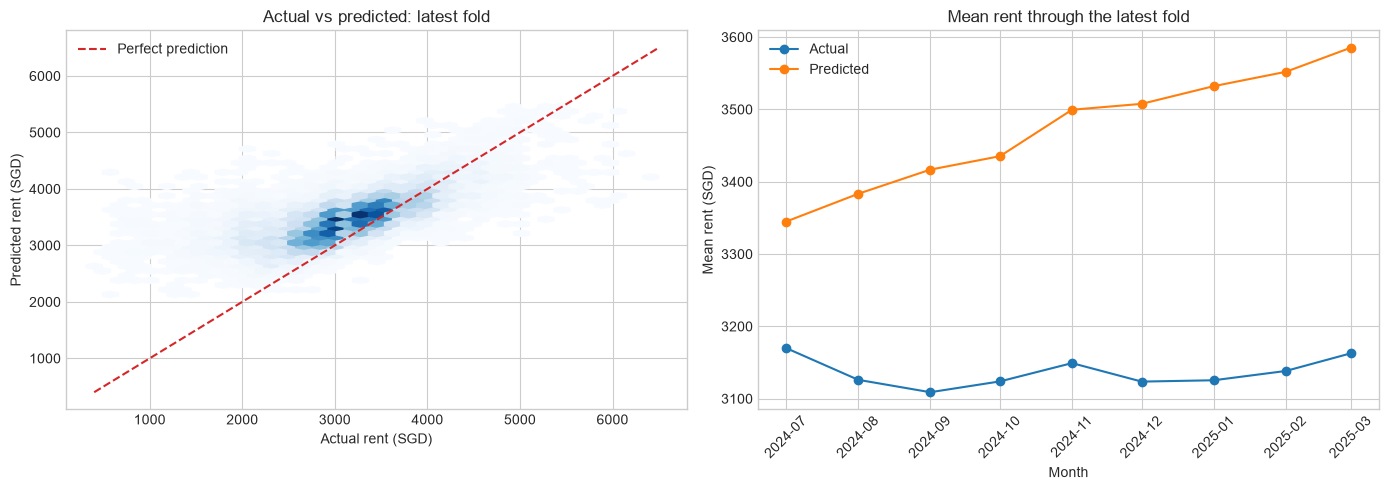

Mean residual (actual − predicted): SGD -335.6


In [8]:
latest = SPLITS[-1]
latest_mask = train["RENT_DATE"].between(
    pd.Timestamp(latest["start"]), pd.Timestamp(latest["end"]), inclusive="left"
)
latest_diagnostics = train.loc[latest_mask, ["RENT_DATE", "TOWN", "FLAT_TYPE", TARGET]].copy()
latest_diagnostics["prediction"] = fold_predictions[(latest["fold"], SELECTED_ALPHA)]
latest_diagnostics["residual"] = latest_diagnostics[TARGET] - latest_diagnostics["prediction"]
latest_diagnostics["absolute_error"] = latest_diagnostics["residual"].abs()
latest_diagnostics["squared_error"] = latest_diagnostics["residual"].pow(2)

monthly_diagnostics = latest_diagnostics.groupby("RENT_DATE").agg(
    actual=(TARGET, "mean"), prediction=("prediction", "mean")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hexbin(
    latest_diagnostics[TARGET], latest_diagnostics["prediction"],
    gridsize=35, mincnt=1, cmap="Blues"
)
limits = [latest_diagnostics[TARGET].min(), latest_diagnostics[TARGET].max()]
axes[0].plot(limits, limits, "--", color="#D62728", label="Perfect prediction")
axes[0].set(title="Actual vs predicted: latest fold", xlabel="Actual rent (SGD)", ylabel="Predicted rent (SGD)")
axes[0].legend()

axes[1].plot(monthly_diagnostics.index, monthly_diagnostics["actual"], marker="o", label="Actual")
axes[1].plot(monthly_diagnostics.index, monthly_diagnostics["prediction"], marker="o", label="Predicted")
axes[1].set(title="Mean rent through the latest fold", xlabel="Month", ylabel="Mean rent (SGD)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Mean residual (actual − predicted): SGD {latest_diagnostics['residual'].mean():,.1f}")

In [9]:
def subgroup_metrics(frame, group_column):
    return (
        frame.groupby(group_column)
        .agg(
            rows=(TARGET, "size"),
            MAE=("absolute_error", "mean"),
            RMSE=("squared_error", lambda values: np.sqrt(values.mean())),
            bias=("residual", "mean"),
        )
        .sort_values("RMSE", ascending=False)
    )

print("Latest-fold error by flat type:")
display(subgroup_metrics(latest_diagnostics, "FLAT_TYPE"))
print("Towns with the highest latest-fold RMSE (minimum 200 validation rows):")
town_errors = subgroup_metrics(latest_diagnostics, "TOWN")
display(town_errors.query("rows >= 200").head(10))

Latest-fold error by flat type:


,rows,MAE,RMSE,bias
FLAT_TYPE,,,,
1-room,10,629.939,702.913,-629.939
2-room,708,491.873,639.980,-471.541
3-room,8562,464.547,608.584,-422.578
executive,1309,423.138,587.902,-154.743
4-room,9468,415.603,570.529,-317.763
5-room,5927,402.174,552.324,-261.757


Towns with the highest latest-fold RMSE (minimum 200 validation rows):


,rows,MAE,RMSE,bias
TOWN,,,,
jurong west,1802,450.069,635.364,-248.475
kallang/whampoa,1001,462.833,631.780,-319.728
bukit merah,1501,447.765,619.303,-310.429
queenstown,1046,461.072,616.029,-337.441
woodlands,1305,441.501,604.488,-368.274
yishun,1337,442.348,600.128,-389.606
geylang,753,442.865,594.621,-338.601
toa payoh,1006,434.615,592.447,-321.029
bedok,1532,436.446,590.816,-360.844


## Interpreting the fitted baseline

The following refit uses only data before the latest validation block. Numeric coefficients correspond to a one-standard-deviation change; categorical coefficients are regularized one-hot adjustments around the intercept. Because correlated address fields can share weight, these coefficients are descriptive—not causal.

In [10]:
latest_start = pd.Timestamp(SPLITS[-1]["start"])
interpretation_train = train[train["RENT_DATE"] < latest_start]
interpretation_preprocessor = make_preprocessor()
X_interpretation = interpretation_preprocessor.fit_transform(interpretation_train[FEATURES])
interpretation_model = Ridge(
    alpha=SELECTED_ALPHA, solver="lsqr", max_iter=10_000, tol=1e-4
).fit(X_interpretation, interpretation_train[TARGET])

coefficient_table = pd.DataFrame({
    "feature": interpretation_preprocessor.get_feature_names_out(),
    "coefficient_sgd": interpretation_model.coef_,
})
display(coefficient_table.nsmallest(12, "coefficient_sgd"))
display(coefficient_table.nlargest(12, "coefficient_sgd"))

,feature,coefficient_sgd
591,categorical__FLAT_TYPE_2-room,-556.714
3677,categorical__PROPERTY_KEY_punggol|109a|edgedal...,-424.393
3968,categorical__PROPERTY_KEY_queenstown|27|ghim m...,-418.979
5518,categorical__PROPERTY_KEY_woodlands|753|woodla...,-360.058
590,categorical__FLAT_TYPE_1-room,-351.381
1726,categorical__PROPERTY_KEY_bukit merah|7|telok ...,-351.381
29,categorical__TOWN_woodlands,-341.625
2957,categorical__PROPERTY_KEY_jurong west|276b|jur...,-337.546
2022,categorical__PROPERTY_KEY_choa chu kang|458|ch...,-330.887
1705,categorical__PROPERTY_KEY_bukit merah|6b|boon ...,-318.740


,feature,coefficient_sgd
322,categorical__STREET_lim liak street,865.923
501,categorical__STREET_tiong bahru road,575.822
312,categorical__STREET_kim cheng street,560.810
9,categorical__TOWN_bukit merah,454.092
349,categorical__STREET_moh guan terrace,430.001
133,categorical__STREET_cantonment road,420.195
12,categorical__TOWN_central,417.903
2,numeric__MONTH_INDEX,413.907
595,categorical__FLAT_TYPE_executive,408.565
23,categorical__TOWN_queenstown,379.725


## How to improve beyond the baseline

The baseline is additive: the same floor-area effect is assumed across towns, dates, and flat types. Its future-fold errors and compressed predictions show where richer models can help. Recommended next experiments, in priority order:

1. **Add processed auxiliary features as an ablation.** Start with HDB latitude/longitude, subzone/planning area, building age/max floor, distance and counts for MRTs, malls, and primary schools. Compare core-only versus core + spatial/building features on exactly the same folds. Add lagged COE and stock aggregates separately; these macro proxies may be noisy, and their missing early history must stay inside the imputation pipeline.
2. **Train CatBoost on native categoricals.** CatBoost can learn nonlinearities and interactions among time, property, location, and flat type without a very wide one-hot matrix. Use the same chronological folds, validation-based early stopping, MAE/RMSE reporting, and no target-derived features. `catboost` is not currently listed in `environment.yml`, so add it explicitly before making the comparison reproducible.
3. **Model temporal drift more flexibly.** Test splines or piecewise trends for `MONTH_INDEX`, and interactions such as month × town and month × flat type. Any rolling target aggregates must use only prior months and be recomputed within every fold.
4. **Improve high-cardinality location handling.** Compare native CatBoost categoricals with cross-fitted target encoding or frequency encoding for `PROPERTY_KEY`/street. Never calculate target encodings on the validation block.
5. **Investigate subgroup residuals.** Focus feature engineering on towns and flat types with high RMSE or persistent bias. Consider robust objectives or a log-target sensitivity check if expensive flats dominate squared error.

A candidate improvement should be accepted only if it lowers RMSE consistently across the expanding windows, not just on one random split.

## Fit on all training data and predict the test set

After model selection, refit the complete preprocessing + Ridge pipeline on all labelled rows. The prediction frame retains `ROW_ID` so row alignment can be checked. Predictions are not clipped: clipping should be treated as a separately validated modelling choice. To create the competition-format `Id,Predicted` CSV with schema and ID validation, run `python scripts/create_ridge_submission.py` from the repository root.

In [11]:
final_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("ridge", Ridge(alpha=SELECTED_ALPHA, solver="lsqr", max_iter=10_000, tol=1e-4)),
])
final_pipeline.fit(train[FEATURES], train[TARGET])
test_prediction = final_pipeline.predict(test[FEATURES])

ridge_test_predictions = pd.DataFrame({
    ROW_ID: test[ROW_ID].to_numpy(),
    TARGET: test_prediction,
})
assert len(ridge_test_predictions) == len(test)
assert ridge_test_predictions[ROW_ID].equals(test[ROW_ID].reset_index(drop=True))
assert np.isfinite(ridge_test_predictions[TARGET]).all()

display(ridge_test_predictions.head())
display(ridge_test_predictions[TARGET].describe().to_frame().T)

,ROW_ID,MONTHLY_RENT
0,0,"3,105.637"
1,1,"3,845.861"
2,2,"3,364.684"
3,3,"3,400.807"
4,4,"3,597.080"


,count,mean,std,min,25%,50%,75%,max
MONTHLY_RENT,"50,000.000","3,628.214",422.760,"2,047.351","3,339.696","3,614.760","3,882.541","5,789.979"
